In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

from experiments_utils import RESULTS_DIR

In [ ]:
ICS26_DIR = RESULTS_DIR / "ics26"
for d in ICS26_DIR.iterdir():
    print(d.name)

ics_quadratic
ics_shifted_gaussians
ics_rosenbrock
ics_rosenbrock_n_min_per_cluster


In [ ]:
# Publication-Quality Plot Settings
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "figure.figsize": (6.5, 4.5),
        "figure.dpi": 100,
        "savefig.dpi": 300,
        "lines.linewidth": 1.5,
        "lines.markersize": 5,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
    }
)
PALETTE = "deep"
COLORS = sns.color_palette(PALETTE)

In [ ]:
def plot_error_with_log_log_fit(
    df,
    error_col1,
    error_col2,
    title1,
    title2,
    error_metric_col="ERROR_METRIC",
    skip_first_n=0,
    dim_col="dim",
):
    # drop rows where error_col1 or error_col2 is  or zero
    df = df[(df[error_col1] > 0) & (df[error_col2] > 0)]
    plt.figure(figsize=(16, 6))
    plt.subplot(1, 2, 1)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y=error_col1,
        hue=dim_col,
        style=error_metric_col,
        marker="o",
        palette=PALETTE,
    )
    for dim in df[dim_col].unique():
        for e in df[error_metric_col].unique():
            subset = df[(df[dim_col] == dim) & (df[error_metric_col] == e)]
            if len(subset) <= 1:
                continue
            X = np.log(subset["n_clusters"].values).reshape(-1, 1)
            y = np.log(subset[error_col1].values)
            if skip_first_n > 0:
                X = X[skip_first_n:]
                y = y[skip_first_n:]
            model = LinearRegression()
            model.fit(X, y)
            x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
            y_fit = model.predict(x_fit.reshape(-1, 1))
            label = rf"$({dim}D) (E={e}) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
            plt.plot(
                np.exp(x_fit), np.exp(y_fit), linestyle="--", color="k", label=label
            )
        plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(error_col1.replace("_", " ").title())
    plt.title(title1)
    plt.legend()
    plt.grid(True, which="both", ls="--", lw=0.5)

    plt.subplot(1, 2, 2)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y=error_col2,
        hue=dim_col,
        style=error_metric_col,
        marker="o",
        palette=PALETTE,
    )
    for dim in df[dim_col].unique():
        for e in df[error_metric_col].unique():
            subset = df[(df[dim_col] == dim) & (df[error_metric_col] == e)]
            if len(subset) <= 1:
                continue
            X = np.log(subset["n_clusters"].values).reshape(-1, 1)
            y = np.log(subset[error_col2].values)
            if skip_first_n > 0:
                X = X[skip_first_n:]
                y = y[skip_first_n:]
            model = LinearRegression()
            model.fit(X, y)
            x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
            y_fit = model.predict(x_fit.reshape(-1, 1))
            label = rf"$({dim}D) (E={e}) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(error_col2.replace("_", " ").title())
    plt.title(title2)
    plt.legend()
    plt.grid(True, which="both", ls="--", lw=0.5)
    plt.show()


def plot_percentage_metrics(df, dim_col="dim"):
    plt.figure(figsize=(24, 7))
    plt.subplot(1, 3, 1)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y="perct_out",
        hue=dim_col,
        style="ERROR_METRIC",
        marker="o",
        palette=PALETTE,
    )
    plt.xscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(r"$\%$ out (perct_out)")
    plt.title(r"$\%$ out vs Number of Cluster")
    plt.ylim(0, 100)
    plt.grid(True, which="both", ls="--", lw=0.5)

    plt.subplot(1, 3, 2)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y="perct_in_good",
        hue=dim_col,
        style="ERROR_METRIC",
        marker="o",
        palette=PALETTE,
    )
    plt.xscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(r"$\%$ in-Good (perct_in_good)")
    plt.ylim(0, 100)
    plt.title(r"$\%$ in-Good vs Number of Cluster")
    plt.grid(True, which="both", ls="--", lw=0.5)

    plt.subplot(1, 3, 3)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y="perct_in_bad",
        hue=dim_col,
        style="ERROR_METRIC",
        marker="o",
        palette=PALETTE,
    )
    plt.xscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(r"$\%$ in-Bad (perct_in_bad)")
    plt.ylim(0, 100)
    plt.title(r"$\%$ in-Bad vs Number of Cluster")
    plt.grid(True, which="both", ls="--", lw=0.5)
    plt.show()

# Problems

In [ ]:
prob_dir = ICS26_DIR / "ics_rosenbrock_n_min_per_cluster"
csv_path = prob_dir / "summary.csv"

df_problem = pd.read_csv(csv_path)
df_problem = df_problem.dropna(subset=["n_clusters"])

if "n_min_per_cluster" in prob_dir.name:
    dim_col = "dim_n_min_per_cluster"
    df_problem[dim_col] = (
        df_problem["dim"].astype(str)
        + "D_"
        + df_problem["N_MIN_PER_CLUSTER"].astype(str)
    )
else:
    dim_col = "dim"

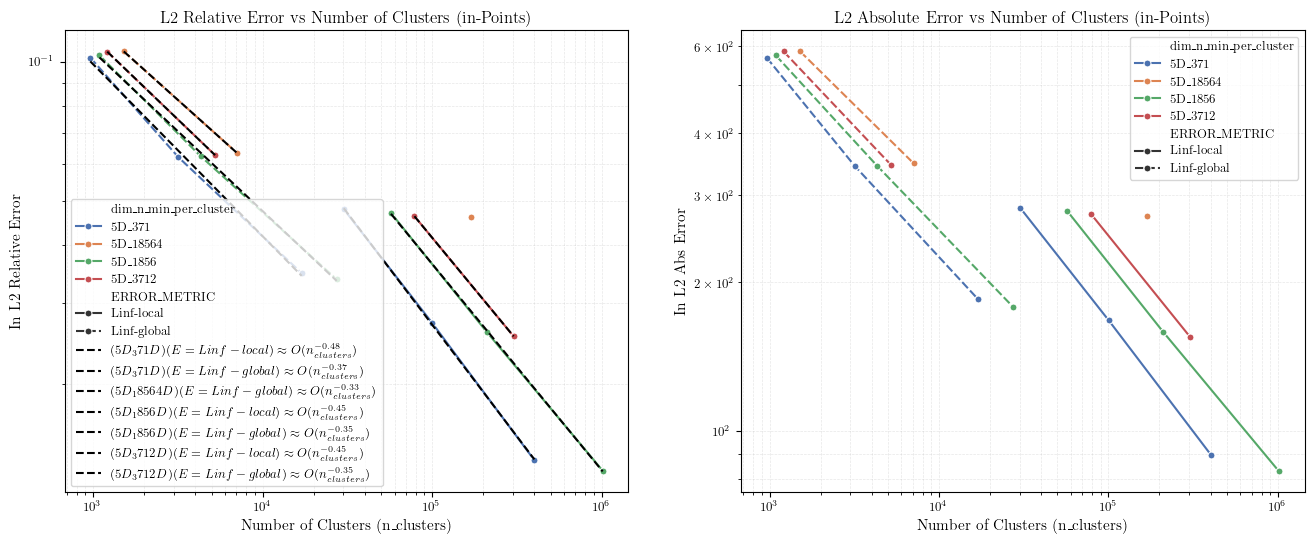

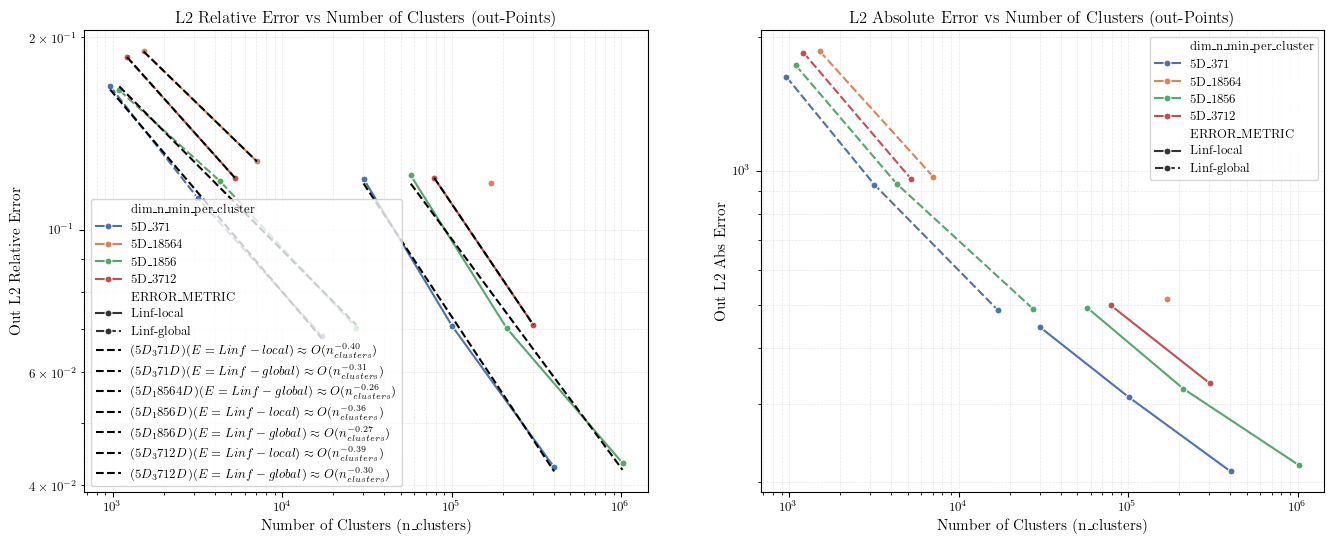

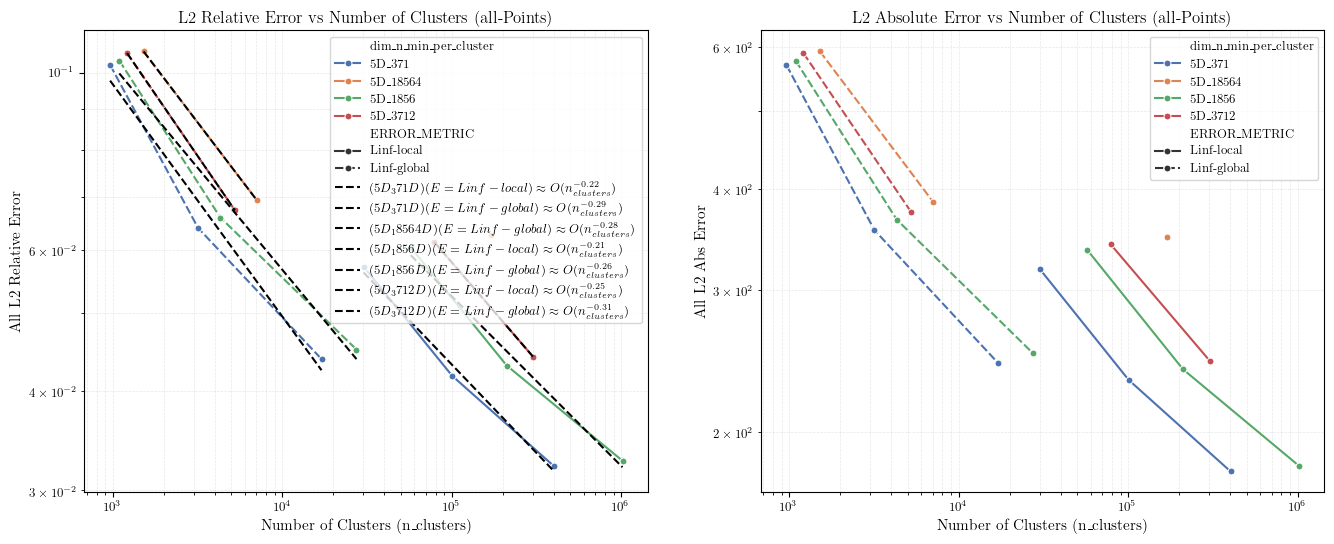

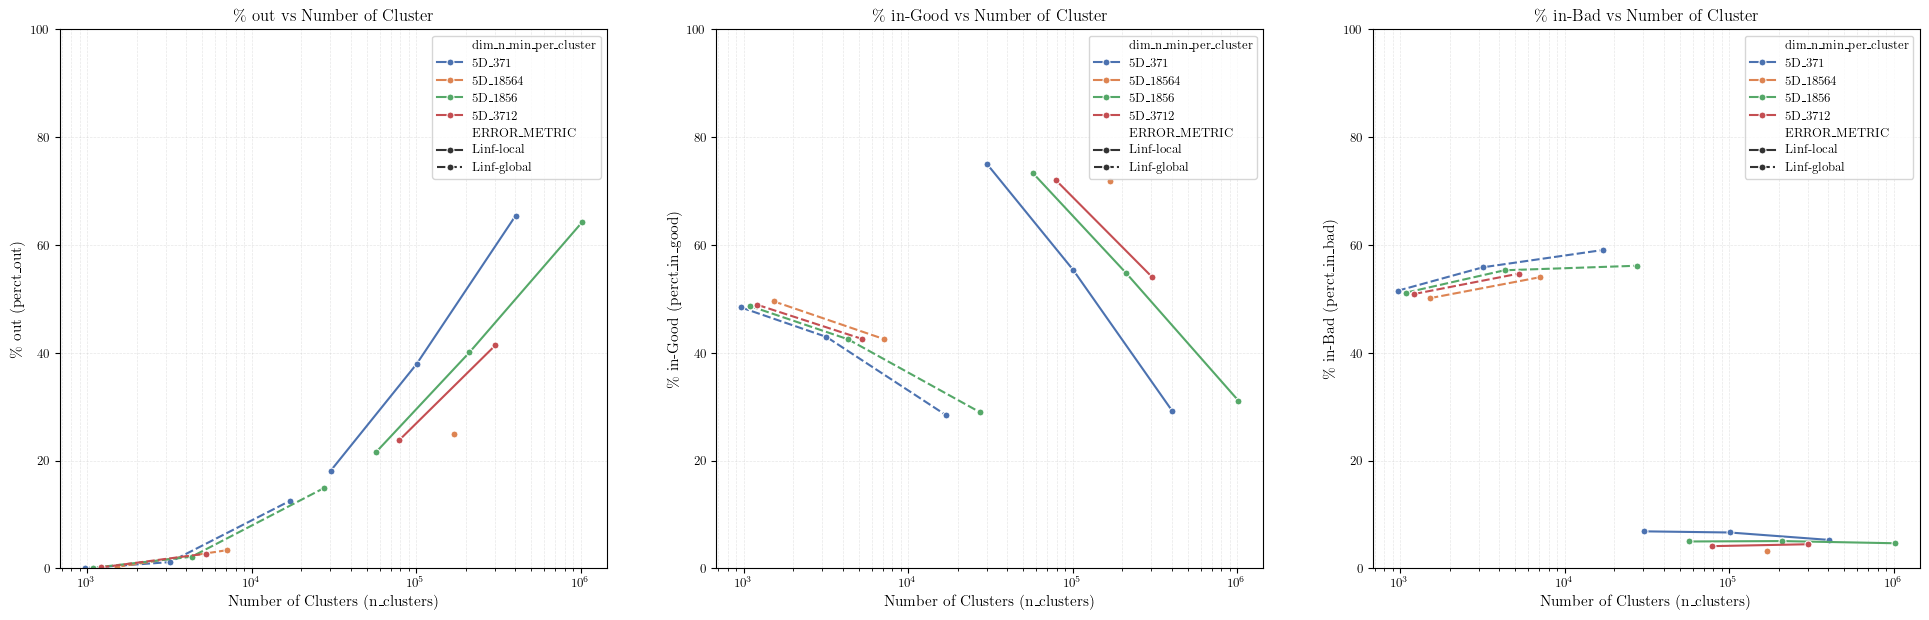

In [ ]:
if "hessian_estimation" in prob_dir.name:
    plot_error_with_log_log_fit(
        df_problem,
        "l2_rel_error",
        "l2_abs_error",
        "L2 Relative Error vs Number of Clusters",
        "L2 Absolute Error vs Number of Clusters",
        error_metric_col="metric",
        skip_first_n=1,
    )
else:
    plot_error_with_log_log_fit(
        df_problem,
        "in_l2_relative_error",
        "in_l2_abs_error",
        "L2 Relative Error vs Number of Clusters (in-Points)",
        "L2 Absolute Error vs Number of Clusters (in-Points)",
        dim_col=dim_col,
    )
    plot_error_with_log_log_fit(
        df_problem,
        "out_l2_relative_error",
        "out_l2_abs_error",
        "L2 Relative Error vs Number of Clusters (out-Points)",
        "L2 Absolute Error vs Number of Clusters (out-Points)",
        dim_col=dim_col,
    )
    plot_error_with_log_log_fit(
        df_problem,
        "all_l2_relative_error",
        "all_l2_abs_error",
        "L2 Relative Error vs Number of Clusters (all-Points)",
        "L2 Absolute Error vs Number of Clusters (all-Points)",
        dim_col=dim_col,
    )
    plot_percentage_metrics(df_problem, dim_col=dim_col)

In [ ]:
def get_renamed_df(df):
    rename_cols = {
        "dim": "D",
        "f_dim": "F Dim",
        "tol": "tol",
        "ERROR_METRIC": "Error Metric",
        "n_clusters": "N Src",
        "in_l2_relative_error": "L2 Rel Err (In)",
        "in_l2_abs_error": "L2 Abs Err (In)",
        "in_ptwise_max_rel_error_linf": "Ptwise Max Rel L-inf Err (In)",
        "in_ptwise_median_rel_error_linf": "Ptwise Median Rel L-inf Err (In)",
        "out_l2_relative_error": "L2 Rel Err (Out)",
        "out_l2_abs_error": "L2 Abs Err (Out)",
        "out_ptwise_max_rel_error_linf": "Ptwise Max Rel L-inf Err (Out)",
        "out_ptwise_median_rel_error_linf": "Ptwise Median Rel L-inf Err (Out)",
        "perct_out": "% Out",
        "perct_in_good": "% In-Good",
        "perct_in_bad": "% In-Bad",
        "n_out": "N Out",
        "all_l2_relative_error": "L2 Rel Err (All)",
        "all_l2_abs_error": "L2 Abs Err (All)",
        "all_ptwise_max_rel_error_linf": "Ptwise Max Rel L-inf Err (All)",
        "all_ptwise_median_rel_error_linf": "Ptwise Median Rel L-inf Err (All)",
        "N_INIT_CLUSTERS": "Init Clusters",
        "N_MIN_PER_CLUSTER": "Min Per Cluster",
        "n_train": "N Train",
        "n_test": "N Test",
        "num_generated_pts": "N Generated Pts",
        "total_f_evals": "Total F Evals",
    }
    df_renamed = df.rename(columns=rename_cols)[list(rename_cols.values())]
    return df_renamed


# if "hessian_estimation" in prob_dir.name:
display(get_renamed_df(df_problem))
get_renamed_df(df_problem).to_clipboard(index=False)

,D,F Dim,tol,Error Metric,N Src,L2 Rel Err (In),L2 Abs Err (In),Ptwise Max Rel L-inf Err (In),Ptwise Median Rel L-inf Err (In),L2 Rel Err (Out),...,L2 Rel Err (All),L2 Abs Err (All),Ptwise Max Rel L-inf Err (All),Ptwise Median Rel L-inf Err (All),Init Clusters,Min Per Cluster,N Train,N Test,N Generated Pts,Total F Evals
0,5,1,0.10,Linf-local,30110,0.047895,282.339720,0.634761,0.034982,0.120052,...,0.057188,318.180753,9.869135,0.042398,92,371,185646,92823,10985164,11230938
1,5,1,0.10,Linf-global,1516,0.105304,584.108352,75.211373,0.100756,0.189661,...,0.106359,591.760181,75.211373,0.101004,92,18564,185646,92823,27957378,28145964
2,5,1,0.10,Linf-global,1090,0.103209,573.268461,45.208805,0.103609,0.165025,...,0.103584,576.323827,45.208805,0.103704,92,1856,185646,92823,1837646,2025380
3,5,1,0.10,Linf-local,57177,0.047010,277.957426,0.678941,0.033561,0.121481,...,0.060448,336.319284,8.810372,0.042746,92,1856,185646,92823,105934866,106234774
4,5,1,0.10,Linf-local,169442,0.045997,271.791258,0.762783,0.031070,0.118216,...,0.062727,349.001540,5.464634,0.041390,92,18564,185646,92823,3145391334,3145915778
5,5,1,0.10,Linf-global,962,0.102097,567.637725,39.681076,0.104346,0.167346,...,0.102283,569.085619,39.681076,0.104396,92,371,185646,92823,190751,378229
6,5,1,0.10,Linf-global,1211,0.105174,583.951984,64.236418,0.102815,0.185826,...,0.105847,588.915836,64.236418,0.102960,92,3712,185646,92823,4309586,4497562
7,5,1,0.10,Linf-local,78662,0.046241,274.573255,0.629388,0.032444,0.120430,...,0.061401,341.622177,5.084176,0.042568,92,3712,185646,92823,291807698,292150576
8,5,1,0.05,Linf-global,5242,0.062732,343.873683,23.595853,0.059864,0.120462,...,0.067278,374.322441,23.595853,0.061475,92,3712,185646,92823,19272658,19468696
9,5,1,0.05,Linf-local,210499,0.025917,158.441358,0.356395,0.018167,0.070185,...,0.043001,239.250164,9.799941,0.029812,92,1856,185646,92823,390500498,391107050


In [ ]:
error_cols = [
    "in_l2_relative_error",
    "in_l2_abs_error",
    "in_ptwise_max_rel_error_linf",
    "in_ptwise_median_rel_error_linf",
    "out_l2_relative_error",
    "out_l2_abs_error",
    "out_ptwise_max_rel_error_linf",
    "out_ptwise_median_rel_error_linf",
    "all_l2_relative_error",
    "all_l2_abs_error",
    "all_ptwise_max_rel_error_linf",
    "all_ptwise_median_rel_error_linf",
]

results_list = []
for dim in df_problem["dim"].unique():
    for error_metric in df_problem["ERROR_METRIC"].unique():
        subset = df_problem[
            (df_problem["dim"] == dim) & (df_problem["ERROR_METRIC"] == error_metric)
        ]

        # Skip if not enough points to fit a line
        if len(subset) <= 1:
            print(f"Skip: dim={dim}, ERROR_METRIC={error_metric}")
            continue

        # Initialize the row with metadata
        row = {"dim": dim, "ERROR_METRIC": error_metric}
        X = np.log(subset["n_clusters"].values).reshape(-1, 1)

        for error_col in error_cols:
            y = np.log(subset[error_col].values)
            model = LinearRegression()
            model.fit(X, y)
            row[error_col] = model.coef_[0]

        results_list.append(row)


# 1. Create DataFrame directly from the list of dicts
fit_results_df = pd.DataFrame(results_list)

# 2. Set 'dim' and 'ERROR_METRIC' as the index
fit_results_df = fit_results_df.set_index(["dim", "ERROR_METRIC"])

# 3. Transpose (T) to flip rows and columns
final_df = fit_results_df.T

# 4. Rename columns to "2D-metric" format
final_df.columns = [f"{dim}D-{metric}" for dim, metric in final_df.columns]

# --- ADDED: Insert Expected Row ---
# Parse 'D' from column name (e.g., "5D-..." -> 5) and calculate -2/D
expected_values = [-2.0 / int(col.split("D-")[0]) for col in final_df.columns]

# Create the new row
expected_row = pd.DataFrame(
    [expected_values], columns=final_df.columns, index=["Expected"]
)

# Concatenate at the top
final_df = pd.concat([expected_row, final_df])
# ----------------------------------

display(final_df)
final_df.to_clipboard()

,5D-Linf-local,5D-Linf-global
Expected,-0.400000,-0.400000
in_l2_relative_error,-0.418876,-0.361280
in_l2_abs_error,-0.391733,-0.376506
in_ptwise_max_rel_error_linf,-0.499040,-0.373005
in_ptwise_median_rel_error_linf,-0.454104,-0.364223
out_l2_relative_error,-0.337854,-0.294266
out_l2_abs_error,-0.248724,-0.416553
out_ptwise_max_rel_error_linf,-0.099673,0.548937
out_ptwise_median_rel_error_linf,-0.375551,-0.286308
all_l2_relative_error,-0.192343,-0.280097


Text(0.5, 1.0, 'Percentage In-Good vs Total F Evals')

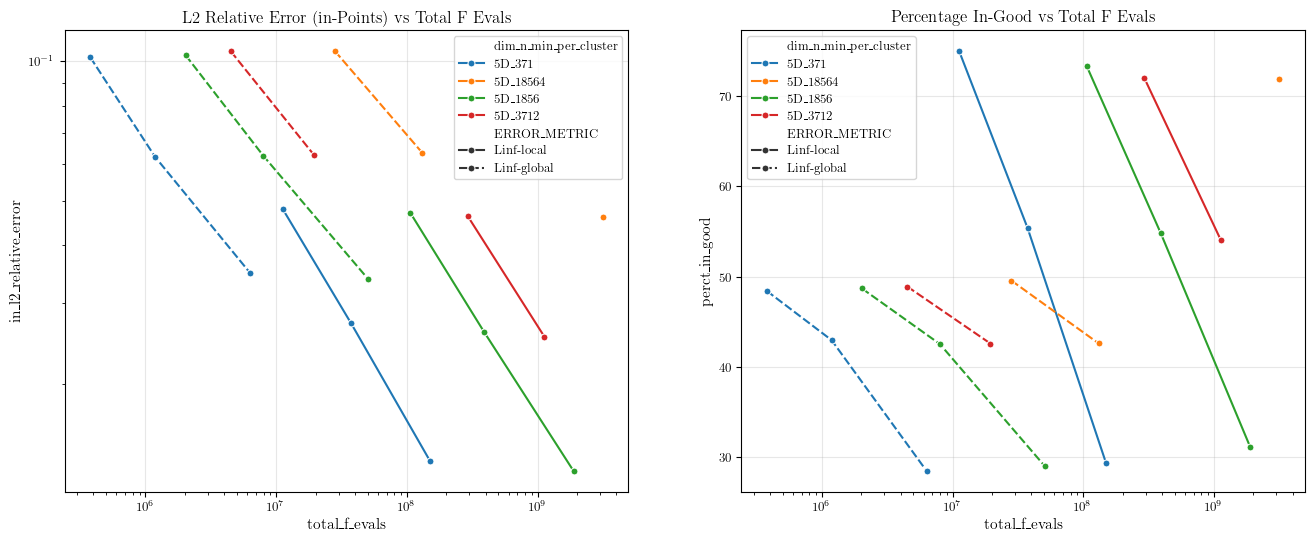

In [189]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_problem,
    x="total_f_evals",
    y="in_l2_relative_error",
    hue=dim_col,
    style="ERROR_METRIC",
    marker="o",
)
plt.xscale("log")
plt.yscale("log")
plt.title("L2 Relative Error (in-Points) vs Total F Evals")

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_problem,
    x="total_f_evals",
    y="perct_in_good",
    hue=dim_col,
    style="ERROR_METRIC",
    marker="o",
)
plt.xscale("log")
plt.title("Percentage In-Good vs Total F Evals")